# Hierrachical Clusturing

## 1.import necessary libs

In [41]:
import pandas as pd
import scipy.cluster.hierarchy as sch
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import  accuracy_score,classification_report,confusion_matrix,recall_score,roc_auc_score,precision_score,roc_curve
from sklearn.ensemble import GradientBoostingClassifier,AdaBoostClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

## 2.data collection

In [3]:
college_data = pd.read_csv("college_list.csv")
college_data

,College_Name,Student_Faculty_Ratio,Annual_Fees_INR,Placement_Percentage,Average_Package_LPA,Infrastructure_Score
0,Indian Institute of Technology Madras - Campus 1,14,113042,59,9.20,8
1,National Institute of Technology Trichy - Camp...,27,115999,67,3.07,7
2,Anna University Chennai - Campus 1,22,47955,50,3.40,9
3,PSG College of Technology - Campus 1,18,67841,43,4.64,8
4,Coimbatore Institute of Technology - Campus 1,15,100640,54,4.66,9
...,...,...,...,...,...,...
495,Thiagarajar College of Engineering - Campus 17,17,106323,56,9.33,5
496,Bannari Amman Institute of Technology - Campus 17,12,39111,76,3.62,7
497,Sri Krishna College of Engineering and Technol...,16,199182,64,3.88,3
498,Sona College of Technology - Campus 17,10,46389,77,9.31,6


## 3.data understanding

In [4]:
college_data.shape

(500, 6)

In [5]:
college_data.isna().sum()

College_Name             0
Student_Faculty_Ratio    0
Annual_Fees_INR          0
Placement_Percentage     0
Average_Package_LPA      0
Infrastructure_Score     0
dtype: int64

In [6]:
college_data.dtypes

College_Name              object
Student_Faculty_Ratio      int64
Annual_Fees_INR            int64
Placement_Percentage       int64
Average_Package_LPA      float64
Infrastructure_Score       int64
dtype: object

## 4.data properation

In [7]:
X=college_data.drop(labels="College_Name" ,axis= 1)

In [14]:
std=StandardScaler()
scaled_x=std.fit_transform(X)
scaled_x=pd.DataFrame(data=scaled_x)
scaled_x

,0,1,2,3,4
0,-0.611689,-0.402753,-0.582199,0.757539,1.010558
1,1.335411,-0.356452,-0.116440,-1.345326,0.511270
2,0.586526,-1.421892,-1.106178,-1.232121,1.509845
3,-0.012581,-1.110515,-1.513717,-0.806745,1.010558
4,-0.461912,-0.596945,-0.873298,-0.799884,1.509845
...,...,...,...,...,...
495,-0.162358,-0.507960,-0.756858,0.802135,-0.487305
496,-0.911243,-1.560372,0.407539,-1.156651,0.511270
497,-0.312135,0.946035,-0.291099,-1.067459,-1.485880
498,-1.210797,-1.446412,0.465759,0.795274,0.011983


## 5.model building

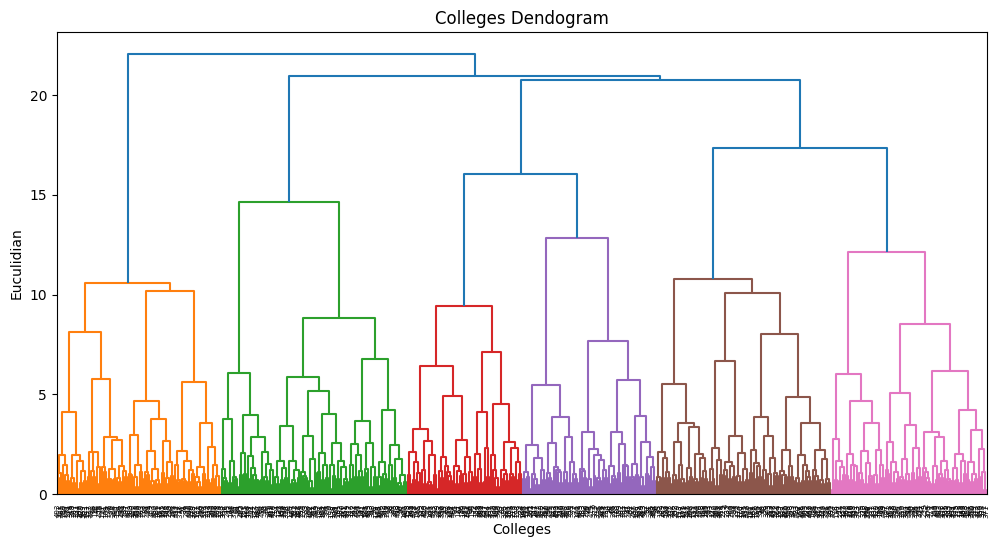

In [18]:
plt.figure(figsize=(12,6))
dendogram = sch.dendrogram(sch.linkage(scaled_x,method='ward'))
plt.title("Colleges Dendogram")
plt.xlabel("Colleges")
plt.ylabel("Euculidian")
plt.show()

In [28]:
hc=AgglomerativeClustering( n_clusters=3, metric='euclidean',linkage='ward')
hc

,n_clusters,3
,metric,'euclidean'
,memory,None
,connectivity,None
,compute_full_tree,'auto'
,linkage,'ward'
,distance_threshold,None
,compute_distances,False


In [29]:
cluster=hc.fit_predict(scaled_x)

### Clustering is done ,lets put this back into original dataset

## Level 2 - data mining - which is clusterining

In [30]:
college_data["Collge_Level"]=cluster
college_data

,College_Name,Student_Faculty_Ratio,Annual_Fees_INR,Placement_Percentage,Average_Package_LPA,Infrastructure_Score,Collge_Level
0,Indian Institute of Technology Madras - Campus 1,14,113042,59,9.20,8,2
1,National Institute of Technology Trichy - Camp...,27,115999,67,3.07,7,0
2,Anna University Chennai - Campus 1,22,47955,50,3.40,9,0
3,PSG College of Technology - Campus 1,18,67841,43,4.64,8,0
4,Coimbatore Institute of Technology - Campus 1,15,100640,54,4.66,9,0
...,...,...,...,...,...,...,...
495,Thiagarajar College of Engineering - Campus 17,17,106323,56,9.33,5,0
496,Bannari Amman Institute of Technology - Campus 17,12,39111,76,3.62,7,0
497,Sri Krishna College of Engineering and Technol...,16,199182,64,3.88,3,1
498,Sona College of Technology - Campus 17,10,46389,77,9.31,6,0


In [31]:
X["Collge_Level"]=cluster
X

,Student_Faculty_Ratio,Annual_Fees_INR,Placement_Percentage,Average_Package_LPA,Infrastructure_Score,Collge_Level
0,14,113042,59,9.20,8,2
1,27,115999,67,3.07,7,0
2,22,47955,50,3.40,9,0
3,18,67841,43,4.64,8,0
4,15,100640,54,4.66,9,0
...,...,...,...,...,...,...
495,17,106323,56,9.33,5,0
496,12,39111,76,3.62,7,0
497,16,199182,64,3.88,3,1
498,10,46389,77,9.31,6,0


In [32]:
X.groupby(by="Collge_Level").agg(["mean"])


,Student_Faculty_Ratio,Annual_Fees_INR,Placement_Percentage,Average_Package_LPA,Infrastructure_Score
,mean,mean,mean,mean,mean
Collge_Level,,,,,
0,20.407051,121853.471154,67.278846,6.954583,6.509615
1,17.159091,156795.136364,85.568182,5.565682,3.965909
2,11.650000,175656.000000,59.790000,8.362500,6.080000


In [34]:
clusters_name={0:"Emerging College",1:"Best college",2:"Mid Level"}
X["Collge Catogaries"]=X["Collge_Level"].map(clusters_name)
X

,Student_Faculty_Ratio,Annual_Fees_INR,Placement_Percentage,Average_Package_LPA,Infrastructure_Score,Collge_Level,Collge Catogaries
0,14,113042,59,9.20,8,2,Mid Level
1,27,115999,67,3.07,7,0,Emerging College
2,22,47955,50,3.40,9,0,Emerging College
3,18,67841,43,4.64,8,0,Emerging College
4,15,100640,54,4.66,9,0,Emerging College
...,...,...,...,...,...,...,...
495,17,106323,56,9.33,5,0,Emerging College
496,12,39111,76,3.62,7,0,Emerging College
497,16,199182,64,3.88,3,1,Best college
498,10,46389,77,9.31,6,0,Emerging College


## Level 4 supervised - so build model

## Data prep for model

In [36]:
SX=X.drop(labels=["Collge_Level","Collge Catogaries"] ,axis= 1)
Sy=X["Collge_Level"]

In [39]:
X_train, X_test, y_train, y_test =train_test_split(SX,Sy,test_size=0.20,train_size=0.80,random_state=12,shuffle=True,stratify=Sy)

([<matplotlib.patches.Wedge at 0x1d391e9c1c0>,
 [Text(-0.42095186141680907, 1.0162674502165874, 'Emerging College'),
  Text(-0.17207745003216413, -1.0864572477508851, 'Best college'),
  Text(0.9379044266480966, -0.5747480199825881, 'Middle')],
 [Text(-0.22961010622735037, 0.5543277001181385, '62.5%'),
  Text(-0.09386042729027133, -0.5926130442277555, '20.0%'),
  Text(0.5115842327171435, -0.31349891999050256, '17.5%')])

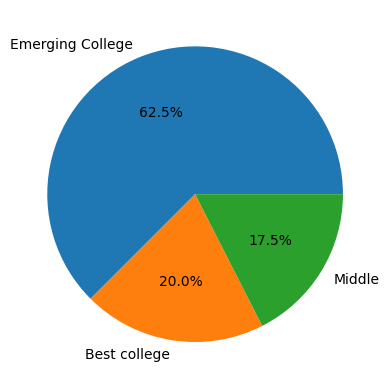

In [42]:
plt.pie(x=y_train.value_counts(),labels=["Emerging College","Best college","Middle"], autopct="%1.1f%%")

In [43]:
rf_model=RandomForestClassifier(n_estimators=100,criterion='gini',max_depth=5,class_weight={0:1,1:3,2:3})
adb_classifier= AdaBoostClassifier()
gbm=GradientBoostingClassifier(n_estimators=50,max_depth=3)
xgbm=XGBClassifier(n_estimators=50)
lgbm=LGBMClassifier(n_estimators=50)

## Model training

In [44]:
adb_classifier.fit(X_train,y_train)

,estimator,None
,n_estimators,50
,learning_rate,1.0
,algorithm,'deprecated'
,random_state,None


In [45]:
rf_model.fit(X_train,y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,5
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [46]:
gbm.fit(X_train,y_train)

,loss,'log_loss'
,learning_rate,0.1
,n_estimators,50
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [47]:
xgbm.fit(X_train,y_train)

,objective,'multi:softprob'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


In [48]:
lgbm.fit(X_train,y_train)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000321 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 357
[LightGBM] [Info] Number of data points in the train set: 400, number of used features: 5
[LightGBM] [Info] Start training from score -0.470004
[LightGBM] [Info] Start training from score -1.742969
[LightGBM] [Info] Start training from score -1.609438
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No furt

,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.1
,n_estimators,50
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


## 7.model testing

In [49]:
y_pred_train_ada=adb_classifier.predict(X_train)

In [50]:
y_pred_train_gb=gbm.predict(X_train)

In [51]:
y_pred_train_xgbm=xgbm.predict(X_train)

In [52]:
y_pred_train_lgbm=lgbm.predict(X_train)

In [53]:
y_pred_train_rf=rf_model.predict(X_train)

## Adaboost report

In [57]:
print(classification_report(y_train,y_pred_train_ada))
print("Accuracy Score for tarining data :" ,accuracy_score(y_train,y_pred_train_ada))
print("Confusion Matrix fir training Data: \n", confusion_matrix(y_train,y_pred_train_ada))
print("Precision Score : ",precision_score(y_train,y_pred_train_ada,average='macro'))
print("Recall Score :", recall_score(y_train,y_pred_train_ada,average='macro'))

              precision    recall  f1-score   support

           0       0.89      0.96      0.92       250
           1       1.00      0.83      0.91        70
           2       0.85      0.78      0.81        80

    accuracy                           0.90       400
   macro avg       0.91      0.85      0.88       400
weighted avg       0.90      0.90      0.90       400

Accuracy Score for tarining data : 0.9
Confusion Matrix fir training Data: 
 [[240   0  10]
 [ 11  58   1]
 [ 18   0  62]]
Precision Score :  0.9138361256811122
Recall Score : 0.8545238095238096


## RF

In [59]:
print(classification_report(y_train,y_pred_train_rf))
print("Accuracy Score for tarining data :" ,accuracy_score(y_train,y_pred_train_rf))
print("Confusion Matrix fir training Data: \n", confusion_matrix(y_train,y_pred_train_rf))
print("Precision Score : ",precision_score(y_train,y_pred_train_rf,average='macro'))
print("Recall Score :", recall_score(y_train,y_pred_train_rf,average='macro'))

              precision    recall  f1-score   support

           0       1.00      0.96      0.98       250
           1       0.95      0.99      0.97        70
           2       0.91      1.00      0.95        80

    accuracy                           0.97       400
   macro avg       0.95      0.98      0.96       400
weighted avg       0.97      0.97      0.97       400

Accuracy Score for tarining data : 0.97
Confusion Matrix fir training Data: 
 [[239   4   7]
 [  0  69   1]
 [  0   0  80]]
Precision Score :  0.9514321295143212
Recall Score : 0.9805714285714285
